In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
dates=pd.date_range(
    start="2024-01-01",
    periods=30,
    freq="MS")

In [10]:
dates

DatetimeIndex(['2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01',
               '2024-05-01', '2024-06-01', '2024-07-01', '2024-08-01',
               '2024-09-01', '2024-10-01', '2024-11-01', '2024-12-01',
               '2025-01-01', '2025-02-01', '2025-03-01', '2025-04-01',
               '2025-05-01', '2025-06-01', '2025-07-01', '2025-08-01',
               '2025-09-01', '2025-10-01', '2025-11-01', '2025-12-01',
               '2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01',
               '2026-05-01', '2026-06-01'],
              dtype='datetime64[us]', freq='MS')

In [18]:
np.random.seed(42)
t=np.linspace(100,400,30)

In [19]:
t

array([100.        , 110.34482759, 120.68965517, 131.03448276,
       141.37931034, 151.72413793, 162.06896552, 172.4137931 ,
       182.75862069, 193.10344828, 203.44827586, 213.79310345,
       224.13793103, 234.48275862, 244.82758621, 255.17241379,
       265.51724138, 275.86206897, 286.20689655, 296.55172414,
       306.89655172, 317.24137931, 327.5862069 , 337.93103448,
       348.27586207, 358.62068966, 368.96551724, 379.31034483,
       389.65517241, 400.        ])

In [22]:
data=np.random.randint(-50,50,30)

In [23]:
data

array([  1,  42, -36,  21,  10, -30,  32,  36,  24,  24,  37,  49, -27,
       -48, -29,   2, -49,  37, -21, -13, -49,  13,   9, -30, -18,  25,
         7, -29,  38,  -2], dtype=int32)

In [24]:
sales=t+data

In [25]:
sales

array([101.        , 152.34482759,  84.68965517, 152.03448276,
       151.37931034, 121.72413793, 194.06896552, 208.4137931 ,
       206.75862069, 217.10344828, 240.44827586, 262.79310345,
       197.13793103, 186.48275862, 215.82758621, 257.17241379,
       216.51724138, 312.86206897, 265.20689655, 283.55172414,
       257.89655172, 330.24137931, 336.5862069 , 307.93103448,
       330.27586207, 383.62068966, 375.96551724, 350.31034483,
       427.65517241, 398.        ])

In [26]:
df=pd.DataFrame({
    "date":dates,
    "sales":sales
})

In [27]:
df.head(4)

,date,sales
0,2024-01-01,101.000000
1,2024-02-01,152.344828
2,2024-03-01,84.689655
3,2024-04-01,152.034483


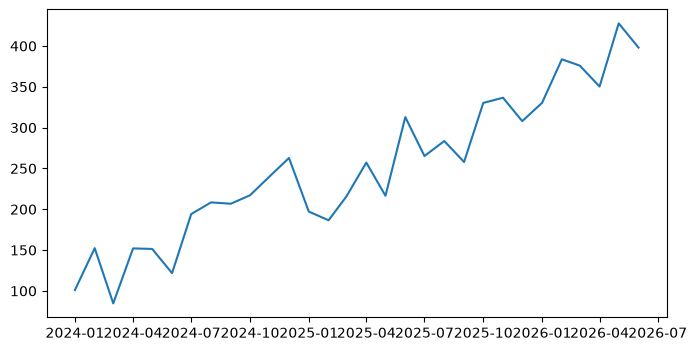

In [29]:
plt.figure(figsize=(8,4))
plt.plot(df["date"],df["sales"])
plt.show()

In [30]:
df["lag1"]=df["sales"].shift(1)

In [32]:
df.head(3)

,date,sales,lag1
0,2024-01-01,101.000000,NaN
1,2024-02-01,152.344828,101.000000
2,2024-03-01,84.689655,152.344828


In [33]:
df["lag2"]=df["sales"].shift(2)
df["lag3"]=df["sales"].shift(3)

In [34]:
df.head(6)

,date,sales,lag1,lag2,lag3
0,2024-01-01,101.000000,NaN,NaN,NaN
1,2024-02-01,152.344828,101.000000,NaN,NaN
2,2024-03-01,84.689655,152.344828,101.000000,NaN
3,2024-04-01,152.034483,84.689655,152.344828,101.000000
4,2024-05-01,151.379310,152.034483,84.689655,152.344828
5,2024-06-01,121.724138,151.379310,152.034483,84.689655


In [35]:
df=df.dropna()

In [36]:
df.head(5)

,date,sales,lag1,lag2,lag3
3,2024-04-01,152.034483,84.689655,152.344828,101.000000
4,2024-05-01,151.379310,152.034483,84.689655,152.344828
5,2024-06-01,121.724138,151.379310,152.034483,84.689655
6,2024-07-01,194.068966,121.724138,151.379310,152.034483
7,2024-08-01,208.413793,194.068966,121.724138,151.379310


In [37]:
df=df.drop(columns=["date"])

In [38]:
df.head(2)

,sales,lag1,lag2,lag3
3,152.034483,84.689655,152.344828,101.000000
4,151.379310,152.034483,84.689655,152.344828


In [40]:
# Divide into X and y
X=df.drop(columns=["sales"])
y=df["sales"]

In [41]:
X.head(2)

,lag1,lag2,lag3
3,84.689655,152.344828,101.000000
4,152.034483,84.689655,152.344828


In [43]:
from sklearn.linear_model import LinearRegression

In [46]:
split_index=int(len(X)*0.8)

In [47]:
split_index

21

In [48]:
X_train=X.iloc[:split_index]
X_test=X.iloc[split_index:]

In [49]:
X_train.shape,X_test.shape

((21, 3), (6, 3))

In [50]:
y_train=y.iloc[:split_index]
y_test=y.iloc[split_index:]

In [51]:
y_train.shape,y_test.shape

((21,), (6,))

In [53]:
re=LinearRegression()

In [55]:
re.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.32,0.28,0.25]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['lag1','lag2','lag3']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,50.38
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [61]:

y_pred=re.predict(X_test)

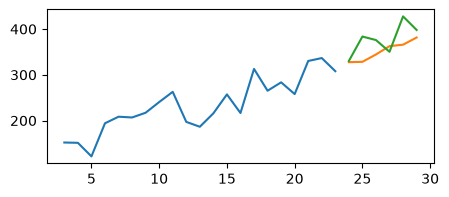

In [62]:
plt.figure(figsize=(5,2))

plt.plot(y_train)

plt.plot(y_test.index,y_pred)
plt.plot(y_test)
plt.show()

In [63]:
re.coef_

array([0.32072185, 0.28029378, 0.25472465])